# Experiment 06: Training against validation by tree size

Card: [exp06_train_gap.md](../../experiments/exp06_train_gap.md)


In [1]:
import os
import sys
from time import perf_counter, strftime

import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from mlflow.entities import Metric

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, MLFLOW_URI
from ashrae.tuning import make_folds, progress

SMOKE = os.environ.get("SMOKE") == "1"
LEARNING_RATE = 0.1
EXP03_SESSION = (
    "2026-10-11 12:25:43"  # exp03 stage A: tree counts and validation curves to match
)
if SMOKE:
    EXPERIMENT = "ashrae-baseline-train_gap-smoke"
    TRAIN = True
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL, N_SCORED = 20_000, 5_000, 5_000
    TREES = {7: 30, 15: 20}
    CURVE_EVERY = 10
    FIGURE = None
else:
    EXPERIMENT = "ashrae-baseline-train_gap"
    TRAIN = False  # exp06 already ran; True retrains it under a new session
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL, N_SCORED = (
        2_000_000,
        500_000,
        500_000,
    )  # N_SCORED: training rows scored each tree
    TREES = None  # read from exp03 below
    CURVE_EVERY = 10
    FIGURE = "../../figures/exp06_train_gap.png"
SESSION = strftime("%Y-%m-%d %H:%M:%S") if TRAIN else "2026-10-11 18:27:13"

mlflow.set_tracking_uri(MLFLOW_URI)
client = mlflow.MlflowClient()
exp03 = mlflow.search_runs(
    experiment_names=["ashrae-baseline-tree_size"],
    filter_string=f"tags.stage = 'A' and tags.session = '{EXP03_SESSION}'",
)
exp03 = exp03.assign(leaves=exp03["params.num_leaves"].astype(int))
if TREES is None:
    TREES = exp03.groupby("leaves")["metrics.trial_trees"].first().astype(int).to_dict()
mlflow.set_experiment(EXPERIMENT)
TREES

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{31: 3874, 63: 1980, 127: 1736, 255: 1056}

## Training


In [2]:
if TRAIN:
    folds = make_folds({f: FOLDS[f] for f in FOLD_NAMES}, N_TRAIN, N_VAL)
    rng = np.random.default_rng(0)
    for d in folds.values():
        d["scored"] = rng.choice(len(d["y_train"]), N_SCORED, replace=False)

    ROWS = ["train", "all", "clean"]
    for leaves, trees in TREES.items():
        name = f"{leaves} leaves"
        for fold, d in folds.items():
            history = {}
            start = perf_counter()
            lgb.LGBMRegressor(
                n_estimators=trees,
                learning_rate=LEARNING_RATE,
                num_leaves=leaves,
                metric="rmse",
                random_state=0,
                verbose=-1,
            ).fit(
                d["X_train"],
                d["y_train"],
                eval_X=(d["X_train"].iloc[d["scored"]], d["X_val"], d["X_val"][d["clean"]]),
                eval_y=(d["y_train"][d["scored"]], d["y_val"], d["y_val"][d["clean"]]),
                eval_names=ROWS,
                callbacks=[
                    lgb.record_evaluation(history),
                    progress(f"{name} | {fold}", trees),
                ],  # no early stopping
            )
            seconds = perf_counter() - start
            # LightGBM's rmse on log1p values: RMSLE except that negative predictions aren't clipped at 0
            curve = {rows: np.array(history[rows]["rmse"]) for rows in ROWS}
            with mlflow.start_run(
                run_name=f"{name} | {fold}",
                tags={
                    "session": SESSION,
                    "stage": "gap",
                    "model": "lgbm_building",
                    "notebook": "exp06_train_gap",
                    "fold": fold,
                    "trial": name,
                },
            ) as run:
                mlflow.log_params(
                    {
                        "learning_rate": LEARNING_RATE,
                        "num_leaves": leaves,
                        "trees": trees,
                        "n_train": N_TRAIN,
                        "n_val": N_VAL,
                        "n_scored": N_SCORED,
                    }
                )
                mlflow.log_metrics(
                    {
                        "train_rmsle": curve["train"][-1],
                        "val_rmsle": curve["all"][-1],
                        "val_rmsle_clean": curve["clean"][-1],
                        "gap": curve["clean"][-1] - curve["train"][-1],
                        "train_seconds": seconds,
                    }
                )
                client.log_batch(
                    run.info.run_id,
                    metrics=[
                        Metric(
                            f"{'train' if rows == 'train' else 'val'}_rmsle_curve_{rows}",
                            float(curve[rows][i]),
                            0,
                            i + 1,
                        )
                        for rows in ROWS
                        for i in range(CURVE_EVERY - 1, trees, CURVE_EVERY)
                    ],
                )

fold data: 100%|██████████| 4/4 [00:05<00:00,  1.25s/fold]
31 leaves | Jan–Mar: 100%|██████████| 3874/3874 [00:52<00:00, 74.08tree/s, best 1.4080 at 3865]            
31 leaves | Apr–Jun: 100%|██████████| 3874/3874 [00:52<00:00, 74.16tree/s, best 1.2042 at 3750]            
31 leaves | Jul–Sep: 100%|██████████| 3874/3874 [00:52<00:00, 74.18tree/s, best 1.0342 at 3850]            
31 leaves | Oct–Dec: 100%|██████████| 3874/3874 [00:52<00:00, 73.35tree/s, best 1.0945 at 3496]            
63 leaves | Jan–Mar: 100%|██████████| 1980/1980 [00:42<00:00, 46.09tree/s, best 1.4090 at 1931]            
63 leaves | Apr–Jun: 100%|██████████| 1980/1980 [00:43<00:00, 45.97tree/s, best 1.2051 at 1966]            
63 leaves | Jul–Sep: 100%|██████████| 1980/1980 [00:43<00:00, 45.89tree/s, best 1.0406 at 1980]            
63 leaves | Oct–Dec: 100%|██████████| 1980/1980 [00:42<00:00, 46.21tree/s, best 1.0957 at 1736]            
127 leaves | Jan–Mar: 100%|██████████| 1736/1736 [01:02<00:00, 27.97tree/s, b

## Results


max |RMSLE difference| against exp03 validation curves: 0.00e+00


,trees,train,val,val_clean,gap
leaves,,,,,
31,3874,0.6744,1.1858,0.9172,0.2428
63,1980,0.6631,1.1879,0.9188,0.2557
127,1736,0.5994,1.1819,0.9119,0.3125
255,1056,0.5774,1.1805,0.9098,0.3324


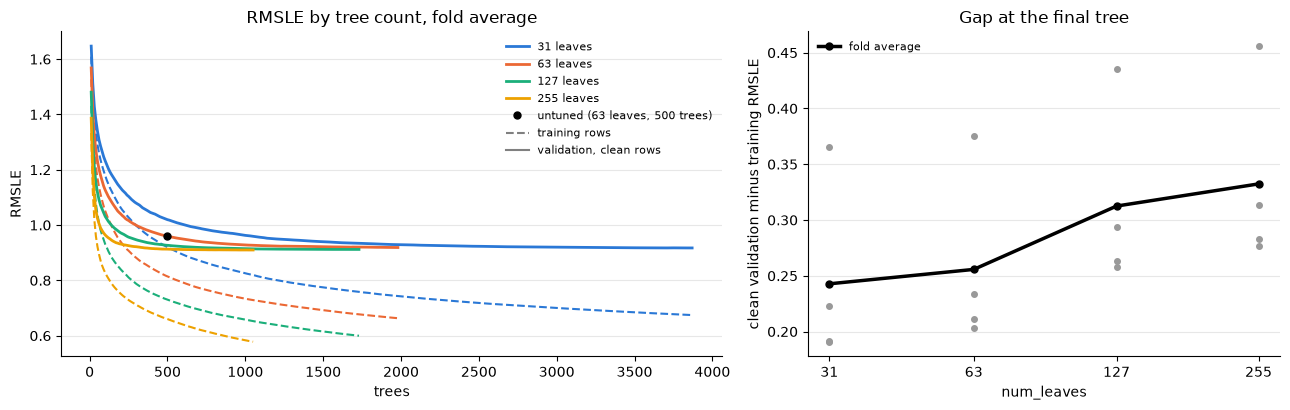

In [3]:
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT],
    filter_string=f"tags.stage = 'gap' and tags.session = '{SESSION}'",
)
runs = runs.assign(leaves=runs["params.num_leaves"].astype(int))
leaves_run = sorted(runs.leaves.unique())


def history(run_id, key):
    return pd.Series(
        {m.step: m.value for m in client.get_metric_history(run_id, key)}
    ).sort_index()


def mean_curve(leaves, key):
    return pd.concat(
        [history(r, key) for r in runs[runs.leaves == leaves].run_id], axis=1
    ).mean(axis=1)


# Reproducibility: the retrained validation curves against exp03's, on the trees both logged
if not SMOKE:
    diffs = []
    for _, r in runs.iterrows():
        old = exp03[
            (exp03.leaves == r.leaves) & (exp03["tags.fold"] == r["tags.fold"])
        ].run_id.item()
        new_c, old_c = history(r.run_id, "val_rmsle_curve_all"), history(
            old, "val_rmsle_curve_all"
        )
        diffs.append((new_c - old_c).dropna().abs().max())
    print(f"max |RMSLE difference| against exp03 validation curves: {max(diffs):.2e}")

summary = runs.groupby("leaves").agg(
    trees=("params.trees", "first"),
    train=("metrics.train_rmsle", "mean"),
    val=("metrics.val_rmsle", "mean"),
    val_clean=("metrics.val_rmsle_clean", "mean"),
    gap=("metrics.gap", "mean"),
)

COLORS = dict(zip(leaves_run, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.4, 1]}
)

ax = axes[0]
for leaves in leaves_run:
    train, clean = mean_curve(leaves, "train_rmsle_curve_train"), mean_curve(
        leaves, "val_rmsle_curve_clean"
    )
    ax.plot(train.index, train, color=COLORS[leaves], lw=1.5, ls="--")
    ax.plot(clean.index, clean, color=COLORS[leaves], lw=2, label=f"{leaves} leaves")
if 63 in leaves_run and not SMOKE:  # untuned lgbm_building: 63 leaves, 500 trees
    clean = mean_curve(63, "val_rmsle_curve_clean")
    ax.plot(
        500,
        clean[500],
        "o",
        color="black",
        ms=5,
        label="untuned (63 leaves, 500 trees)",
    )
ax.plot([], [], color="gray", ls="--", label="training rows")
ax.plot([], [], color="gray", label="validation, clean rows")
ax.set(title="RMSLE by tree count, fold average", xlabel="trees", ylabel="RMSLE")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
for leaves in leaves_run:
    gap = mean_curve(leaves, "val_rmsle_curve_clean") - mean_curve(
        leaves, "train_rmsle_curve_train"
    )
    ax.plot(gap.index, gap, color=COLORS[leaves], lw=2, label=f"{leaves} leaves")
if 63 in leaves_run and not SMOKE:
    gap = mean_curve(63, "val_rmsle_curve_clean") - mean_curve(
        63, "train_rmsle_curve_train"
    )
    ax.plot(
        500,
        gap[500],
        "o",
        color="black",
        ms=5,
        label="untuned (63 leaves, 500 trees)",
    )
ax.set(
    title="Gap by tree count, fold average",
    xlabel="trees",
    ylabel="clean validation minus training RMSLE",
)
ax.legend(frameon=False, fontsize=8)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in runs.run_id:
        client.log_artifact(run_id, FIGURE)

display(summary.round(4))